# MSH 3-T-junction array: tensor networks vs exact diagonalization

Compares the two implementations of the 3-T-junction array, number by number:

| Files | Written by | Method |
|---|---|---|
| `msh_array_ldos_tn.csv`, `msh_gate_density_tn_{Z,X}.csv` | `msh_tjunctions_tn.ipynb` (Julia, TensorBinding) | DMRG LDOS; exact evolution of the zero-mode fermions with the same $H(t)$ as the MPO |
| `msh_gate_density_tdvp_{Z,X}.csv`, `msh_gate_dQ_tdvp_{Z,X}.csv` | offline MPS/TDVP run (`msh_gate_density_tdvp.jl`), loaded in section 7 of `msh_tjunctions_tn.ipynb` | MPS/TDVP evolution with the MPO |
| `tjunctions_python_ed_data/*.npz` | `tjunctions_python_ed.ipynb` (Python, kwant) | dense exact diagonalization and exact evolution |

The CSVs are committed; run `tjunctions_python_ed.ipynb` first, in this directory, to write the `.npz` files. This notebook only loads the
files and compares them, so it runs in seconds. The gate quantities (logical phase, rotation angle, leakage, fusion $\Delta Q$) are compared with
kwant in section 8 of `msh_tjunctions_tn.ipynb`.

Each row prints max |Julia − Python| against a tolerance:
- **Dense against dense** (exact evolution in both codes) should agree to round-off.
- **Tensor network against dense** (DMRG LDOS, TDVP) agrees to the truncation error of the method.

The X gate is the run with `rot_Tx = 400`. $\delta n(x, t) = n_1 - n_0$ is taken on the horizontal chain ($y = 0$, $x = -48 \dots 47$), at the
same snapshots in both codes (every 5 time units during the gate, every 1 during the fusion); $\Delta Q(t)$ is summed over all sites.

**Contents**
1. Subgap LDOS
2. Charge density δn(x, t), exact evolution
3. MPS/TDVP: δn(x, t) and ΔQ(t)
4. Summary

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

PY_DIR = "tjunctions_python_ed_data"       # written by tjunctions_python_ed.ipynb

rows = []   # (kind, name, max |Julia − Python|, tolerance)
def check(kind, name, a, b, tol):
    d = float(np.max(np.abs(np.asarray(a) - np.asarray(b))))
    rows.append((kind, name, d, tol))
    print(f"{name:<52s} {d:9.1e}  (tol {tol:.0e})  {'✓' if d <= tol else '✗'}")

def read_csv(name):
    return np.loadtxt(name, delimiter=",", skiprows=1)

def tn_density(name):
    """(t, x) table of a δn CSV (columns t, x, dn; x fastest)."""
    d = read_csv(name)
    ts, xs = np.unique(d[:, 0]), np.unique(d[:, 1])
    return ts, xs, d[:, 2].reshape(ts.size, xs.size)

## 1. Subgap LDOS

Total (particle + hole, spin-summed) LDOS $A(\mathbf r, \omega)$ of the initial setup, Gaussian width 0.01, $|\omega| \le 0.2$, on all 144 sites.
Julia uses the six lowest-|E| states from penalized DMRG (Rayleigh–Ritz in $H$); Python uses every eigenstate of the dense matrix. Inside the
window only those six states contribute, so the difference is the DMRG error.

**Plot.** $A(x, \omega = 0)$ along the horizontal chain, and $A(\omega)$ at the site with the largest zero-energy weight.

LDOS A(r, ω), DMRG (6 states) vs dense                 3.9e-04  (tol 1e-03)  ✓


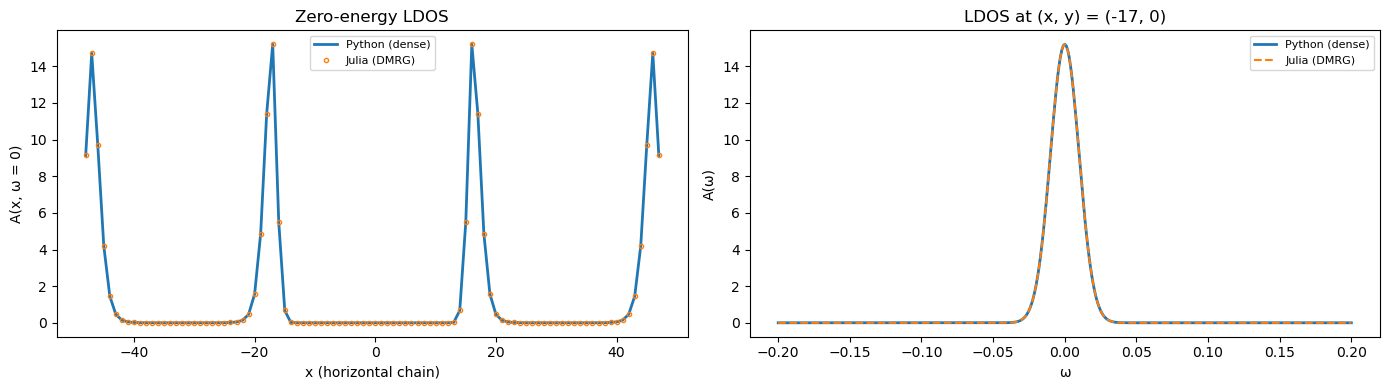

In [2]:
py_l = np.load(os.path.join(PY_DIR, "array_ldos_kwant.npz"))
x, y, om, A_py = py_l["x"], py_l["y"], py_l["omega"], py_l["A"]          # A: (site, ω)
d = read_csv("msh_array_ldos_tn.csv")
tn_map = {(int(r[0]), int(r[1]), round(r[2], 6)): r[3] for r in d}
A_tn = np.array([[tn_map[(int(x[i]), int(y[i]), round(w, 6))] for w in om] for i in range(x.size)])
check("tn", "LDOS A(r, ω), DMRG (6 states) vs dense", A_tn, A_py, 1e-3)

j0 = np.argmin(np.abs(om)); h = np.where(y == 0)[0]; h = h[np.argsort(x[h])]; i_max = np.argmax(A_py[:, j0])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(x[h], A_py[h, j0], lw=2, label="Python (dense)")
ax[0].plot(x[h], A_tn[h, j0], "o", ms=3, mfc="none", label="Julia (DMRG)")
ax[0].set(xlabel="x (horizontal chain)", ylabel="A(x, ω = 0)", title="Zero-energy LDOS"); ax[0].legend(fontsize=8)
ax[1].plot(om, A_py[i_max], lw=2, label="Python (dense)")
ax[1].plot(om, A_tn[i_max], "--", lw=1.5, label="Julia (DMRG)")
ax[1].set(xlabel="ω", ylabel="A(ω)", title=f"LDOS at (x, y) = ({x[i_max]}, {y[i_max]})"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 2. Charge density δn(x, t), exact evolution

Both codes evolve $\psi_A$, $\psi_B$ with midpoint exponential steps ($dt = 0.1$) and the same $H(t)$, so $\delta n$ should agree to round-off over
the whole gate + fusion protocol.

**Plot.** $\log_{10}|\delta n_{\rm Julia} - \delta n_{\rm Python}|$ over the full protocol (dashed: end of the first exchange and of the gate).

exact δn(x, t), Z gate + fusion                        9.0e-15  (tol 1e-09)  ✓
exact δn(x, t), X gate + fusion                        1.5e-14  (tol 1e-09)  ✓


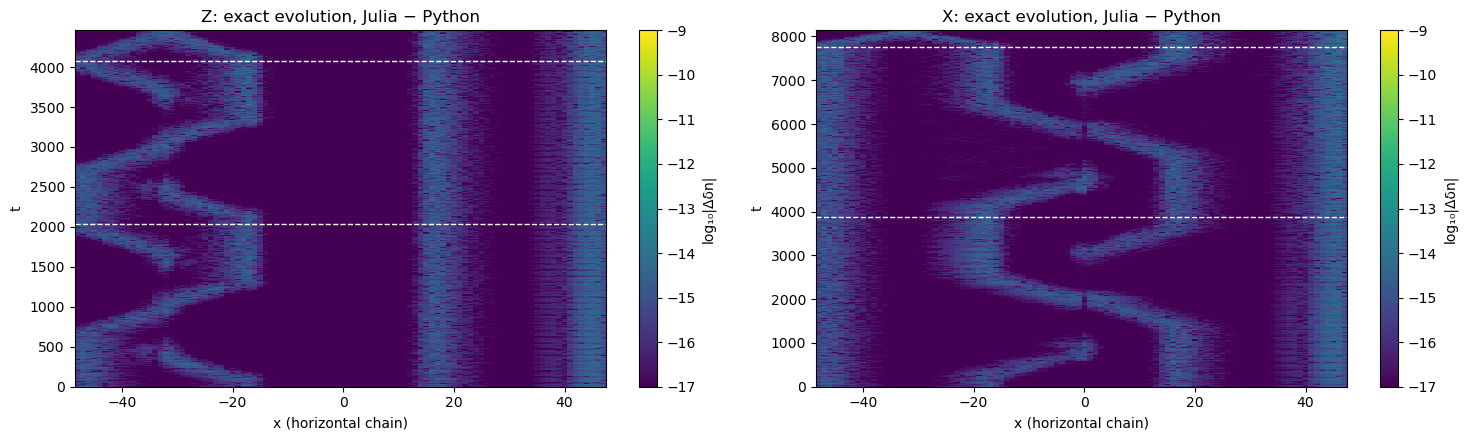

In [3]:
dens = {}
for gate, key in (("Z", "Z"), ("X", "X400")):
    ts, xs_, D_tn = tn_density(f"msh_gate_density_tn_{gate}.csv")
    py = np.load(os.path.join(PY_DIR, f"gate_density_kwant_{key}.npz"))
    assert np.allclose(ts, py["ts"]) and np.array_equal(xs_, py["x"]), "snapshot times or sites differ"
    dens[gate] = dict(ts=ts, x=xs_, Tg=float(py["Tg"]), D_tn=D_tn, D_py=py["D"], dQ_py=py["dQ"])
    check("dense", f"exact δn(x, t), {gate} gate + fusion", D_tn, py["D"], 1e-9)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, (gate, r) in zip(ax, dens.items()):
    im = a.pcolormesh(r["x"], r["ts"], np.log10(np.maximum(np.abs(r["D_tn"] - r["D_py"]), 1e-17)),
                      cmap="viridis", vmin=-17, vmax=-9, shading="nearest", rasterized=True)
    for yl in (r["Tg"] / 2, r["Tg"]):
        a.axhline(yl, color="white", ls="--", lw=1)
    a.set(xlabel="x (horizontal chain)", ylabel="t", title=f"{gate}: exact evolution, Julia − Python")
    fig.colorbar(im, ax=a, label="log₁₀|Δδn|")
fig.tight_layout(); plt.show()

## 3. MPS/TDVP: δn(x, t) and ΔQ(t)

The TDVP run (2-site TDVP on the MPO, `maxdim = 64`, χ saturates at 24) against the Python exact evolution.

**Plot.** Left: $\Delta Q(t)$ during the fusion, TDVP markers on the Python curves. Right: $|\Delta Q_{\rm TDVP} - \Delta Q_{\rm Python}|$ over the full
protocol, with time in units of the gate duration (the fusion starts at 1).

TDVP δn(x, t), Z gate + fusion                         1.4e-06  (tol 1e-05)  ✓
TDVP ΔQ(t), Z gate + fusion                            3.5e-06  (tol 1e-05)  ✓
TDVP δn(x, t), X gate + fusion                         8.8e-07  (tol 1e-05)  ✓
TDVP ΔQ(t), X gate + fusion                            1.9e-06  (tol 1e-05)  ✓


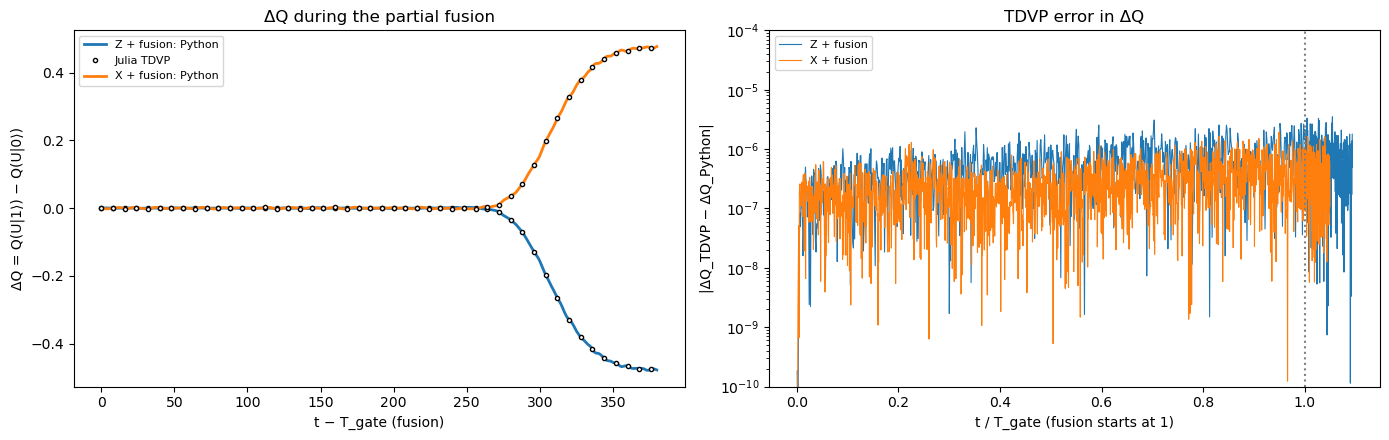

In [4]:
for gate, r in dens.items():
    tsT, xsT, D_tdvp = tn_density(f"msh_gate_density_tdvp_{gate}.csv")
    dq = read_csv(f"msh_gate_dQ_tdvp_{gate}.csv")
    assert np.allclose(tsT, r["ts"]) and np.allclose(dq[:, 0], r["ts"])
    r["dQ_tdvp"] = dq[:, 1]
    check("tn", f"TDVP δn(x, t), {gate} gate + fusion", D_tdvp, r["D_py"], 1e-5)
    check("tn", f"TDVP ΔQ(t), {gate} gate + fusion", dq[:, 1], r["dQ_py"], 1e-5)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for c, (gate, r) in enumerate(dens.items()):
    f = r["ts"] >= r["Tg"] - 1e-6
    ax[0].plot(r["ts"][f] - r["Tg"], r["dQ_py"][f], lw=2, color=f"C{c}", label=f"{gate} + fusion: Python")
    ax[0].plot((r["ts"][f] - r["Tg"])[::8], r["dQ_tdvp"][f][::8], "o", ms=3, mfc="white", mec="k",
               label="Julia TDVP" if c == 0 else None)
    ax[1].semilogy(r["ts"] / r["Tg"], np.maximum(np.abs(r["dQ_tdvp"] - r["dQ_py"]), 1e-16), lw=0.8, color=f"C{c}",
                   label=f"{gate} + fusion")
ax[0].set(xlabel="t − T_gate (fusion)", ylabel="ΔQ = Q(U|1⟩) − Q(U|0⟩)", title="ΔQ during the partial fusion"); ax[0].legend(fontsize=8)
ax[1].axvline(1.0, color="gray", ls=":")
ax[1].set(xlabel="t / T_gate (fusion starts at 1)", ylabel="|ΔQ_TDVP − ΔQ_Python|", ylim=(1e-10, 1e-4),
          title="TDVP error in ΔQ"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 4. Summary

Every row, with its difference and tolerance. Dense-against-dense rows are blue, tensor-network rows orange.

7 of 7 comparisons within tolerance


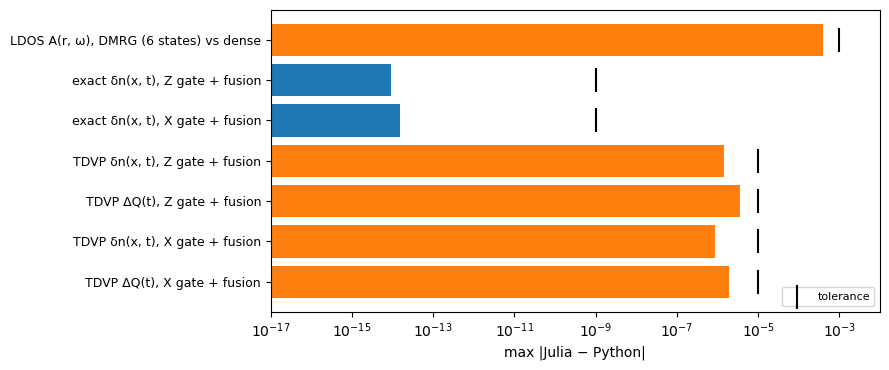

In [5]:
ok = sum(d <= tol for _, _, d, tol in rows)
print(f"{ok} of {len(rows)} comparisons within tolerance")
for kind, name, d, tol in rows:
    if d > tol:
        print(f"  ✗ {name}: {d:.1e} > {tol:.0e}")

fig, ax = plt.subplots(figsize=(9, 0.4 * len(rows) + 1))
yy = np.arange(len(rows))[::-1]
ax.barh(yy, [max(d, 1e-17) for _, _, d, _ in rows], color=["tab:blue" if k == "dense" else "tab:orange" for k, *_ in rows])
ax.scatter([tol for *_, tol in rows], yy, marker="|", s=300, color="k", label="tolerance")
ax.set_xscale("log"); ax.set_xlim(1e-17, 1e-2)
ax.set_yticks(yy); ax.set_yticklabels([name for _, name, _, _ in rows], fontsize=9)
ax.set_xlabel("max |Julia − Python|"); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()